## 1. Import libraries

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import joblib

RANDOM_STATE = 42

## 2. Load the dataset

In [2]:
# Google Colab: if the CSV is not already present, upload it.
DATA_PATH = "Crop_recommendation.csv"

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_files:
            raise FileNotFoundError("Please upload the crop recommendation CSV file.")
        DATA_PATH = csv_files[0]
    except ImportError:
        raise FileNotFoundError(
            "CSV not found. Put Crop_recommendation(2).csv in the notebook folder "
            "or update DATA_PATH to its location."
        )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 3. Initial inspection and data quality

In [3]:
print("Column names:", df.columns.tolist())
print("\\nData types and non-null counts:")
df.info()
print("\\nMissing values per column:")
display(df.isnull().sum().to_frame("missing_values"))
print("\\nDuplicate rows:", df.duplicated().sum())
print("\\nTarget class counts:")
display(df["label"].value_counts().sort_index())

Column names: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 153.0 KB
\nMissing values per column:


,missing_values
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


\nDuplicate rows: 0
\nTarget class counts:


label
apple          100
banana         100
blackgram      100
chickpea       100
coconut        100
coffee         100
cotton         100
grapes         100
jute           100
kidneybeans    100
lentil         100
maize          100
mango          100
mothbeans      100
mungbean       100
muskmelon      100
orange         100
papaya         100
pigeonpeas     100
pomegranate    100
rice           100
watermelon     100
Name: count, dtype: int64

In [4]:
# Basic checks expected for the standard crop recommendation dataset
expected_features = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
target = "label"

missing_columns = [c for c in expected_features + [target] if c not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing expected columns: {missing_columns}")

# Drop exact duplicate rows only if any exist, and report the action.
if df.duplicated().sum() > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Removed exact duplicate rows. New shape:", df.shape)

print("Rows with any missing values:", df.isnull().any(axis=1).sum())

Rows with any missing values: 0


## 4. Exploratory Data Analysis (EDA)

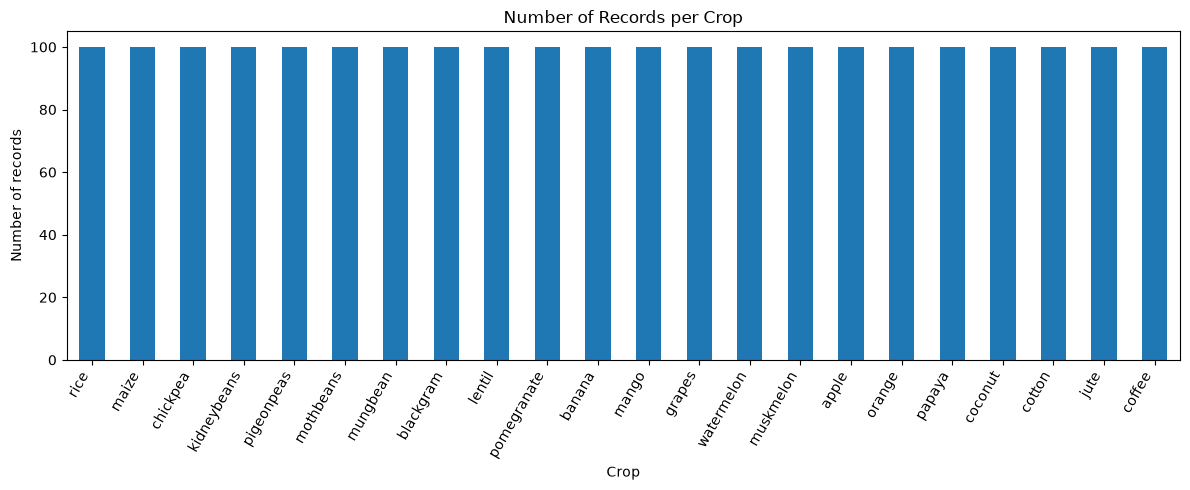

In [5]:
# Distribution of crop labels
plt.figure(figsize=(12, 5))
df["label"].value_counts().plot(kind="bar")
plt.title("Number of Records per Crop")
plt.xlabel("Crop")
plt.ylabel("Number of records")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

In [6]:
# Summary statistics for numerical features
display(df[expected_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


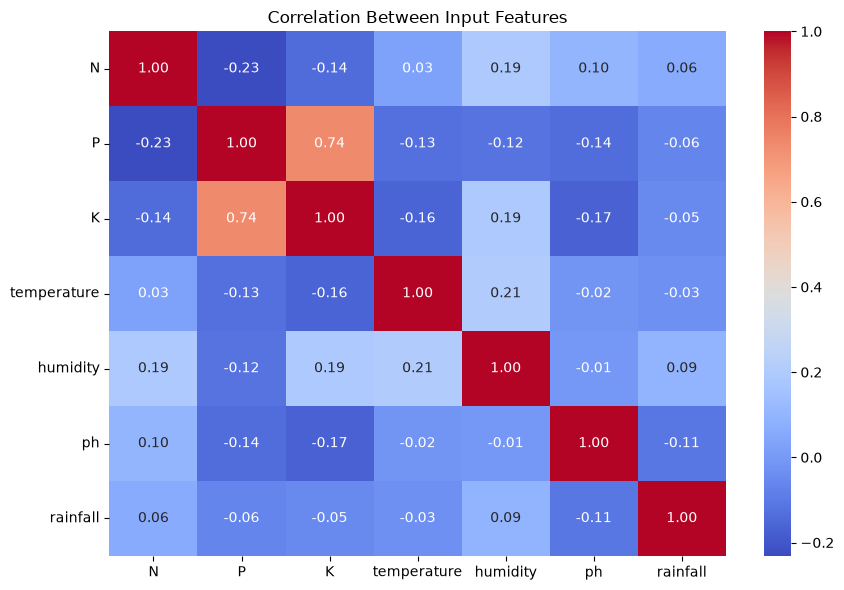

In [7]:
# Correlation heatmap for numeric variables
plt.figure(figsize=(9, 6))
sns.heatmap(df[expected_features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Input Features")
plt.tight_layout()
plt.show()

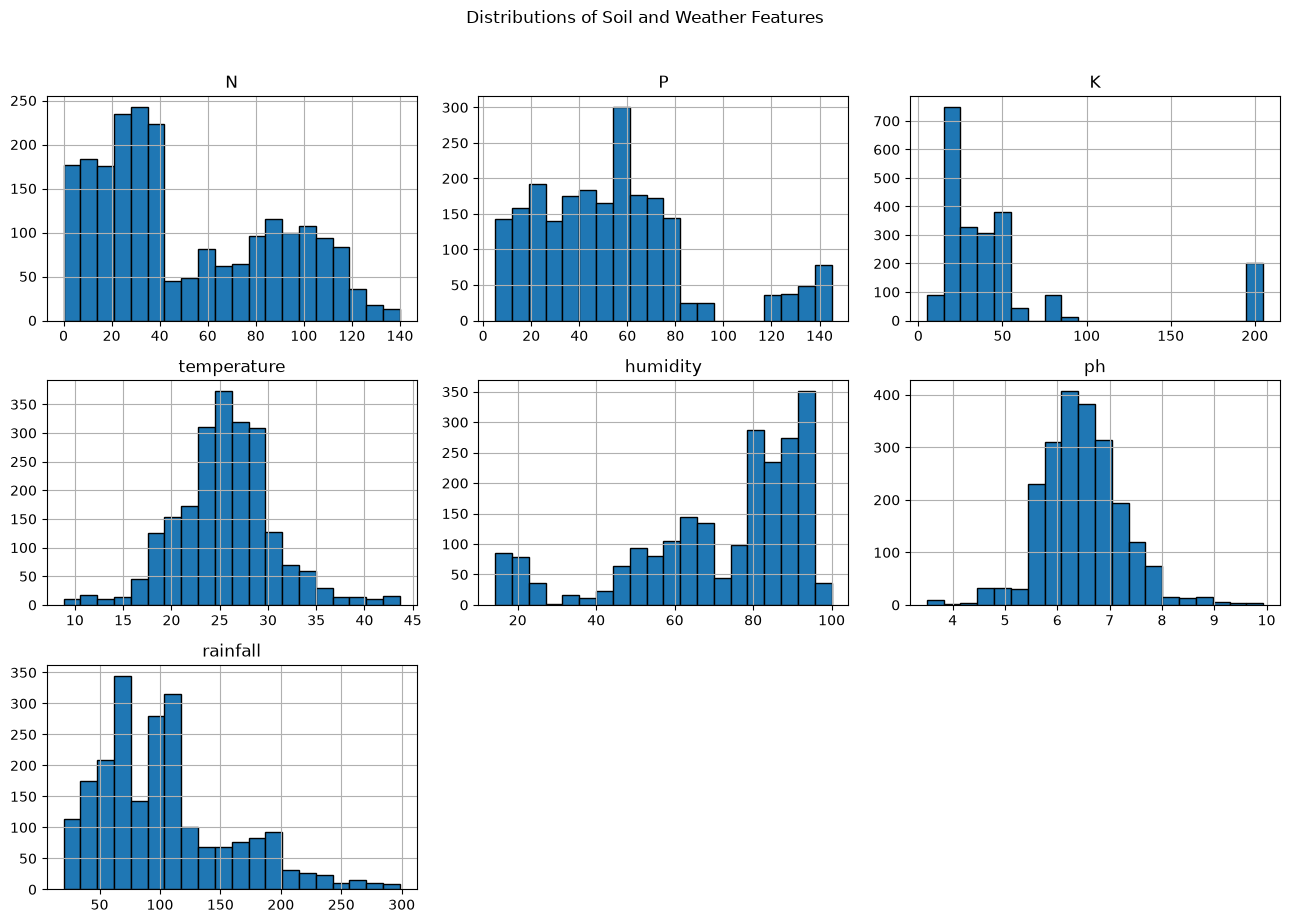

In [8]:
# Feature distributions
df[expected_features].hist(figsize=(13, 9), bins=20, edgecolor="black")
plt.suptitle("Distributions of Soil and Weather Features", y=1.02)
plt.tight_layout()
plt.show()

## 5. Prepare features and target

In [9]:
X = df[expected_features].copy()
y = df[target].copy()

# Stratification preserves the crop proportions in both train and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Training crop distribution (first few):")
display(y_train.value_counts().head())

Training set: (1760, 7)
Test set: (440, 7)
Training crop distribution (first few):


label
orange         80
grapes         80
kidneybeans    80
mothbeans      80
cotton         80
Name: count, dtype: int64

## 6. Train and compare classification models

We compare Decision Tree, Random Forest, KNN, and SVM using the same stratified train/test split.
Scaling is included in the KNN and SVM pipelines because these algorithms are sensitive to feature scales.
Tree models do not require scaling.

In [10]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    trained_models[name] = model
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (macro)": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, predictions, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, predictions, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1-score (macro)", ascending=False).reset_index(drop=True)
display(results_df.style.format({
    "Accuracy": "{:.4f}", "Precision (macro)": "{:.4f}",
    "Recall (macro)": "{:.4f}", "F1-score (macro)": "{:.4f}"
}))

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Random Forest,0.9955,0.9957,0.9955,0.9955
1,SVM,0.9841,0.9856,0.9841,0.9840
2,Decision Tree,0.9795,0.9806,0.9795,0.9794
3,KNN,0.9795,0.9804,0.9795,0.9793


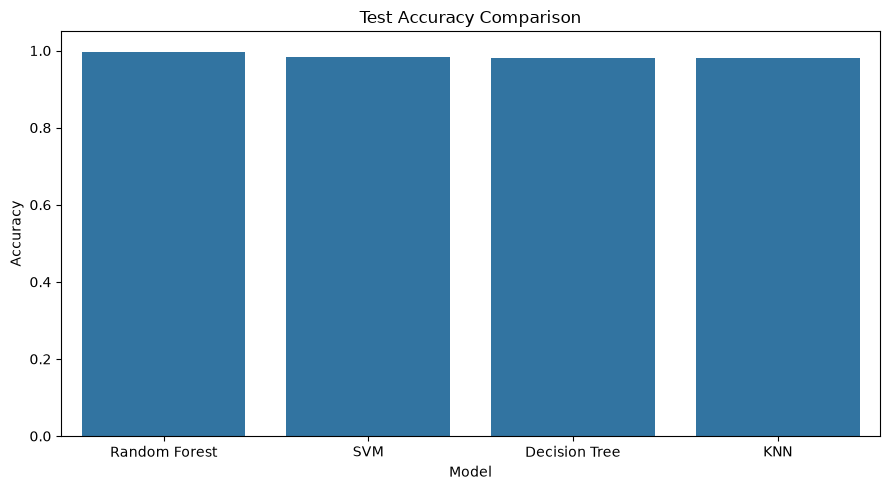

In [11]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="Accuracy")
plt.ylim(0, 1.05)
plt.title("Test Accuracy Comparison")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()

## 7. Evaluate the best model

Best model based on macro F1-score: Random Forest
\nClassification report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      

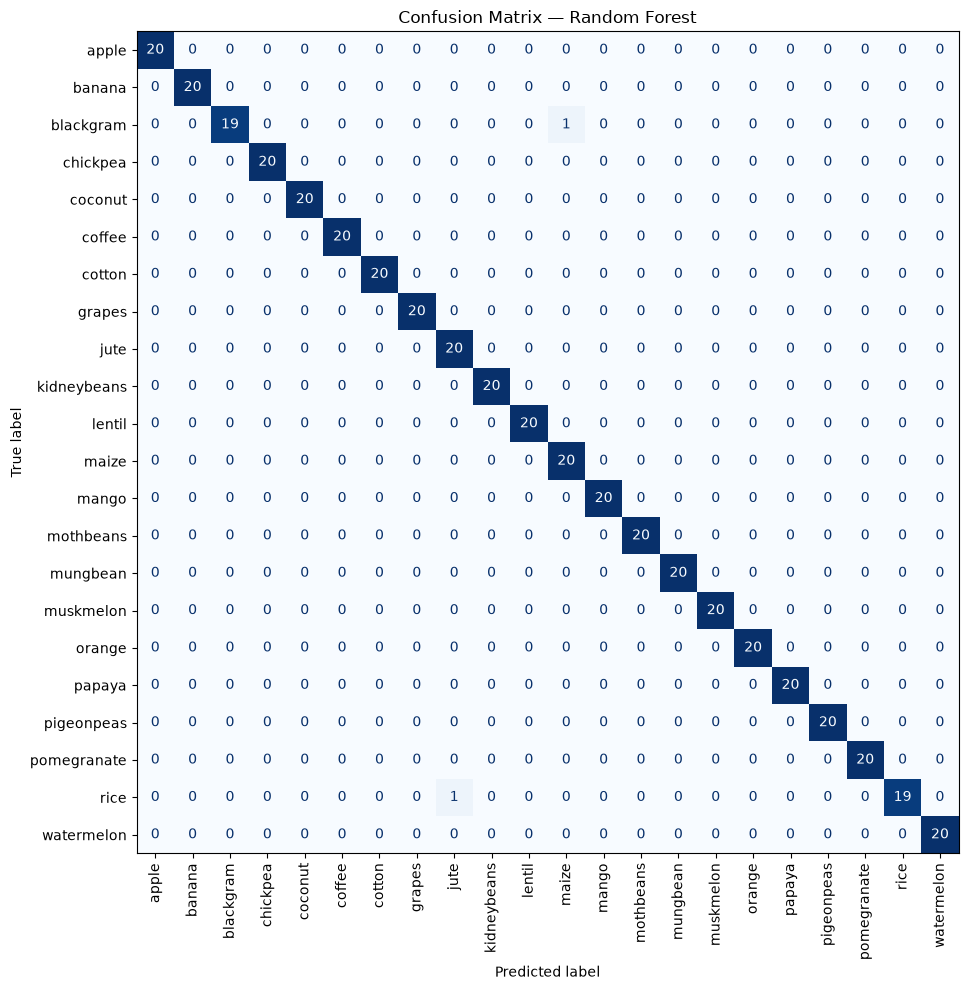

In [12]:
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
y_pred = best_model.predict(X_test)

print("Best model based on macro F1-score:", best_name)
print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, xticks_rotation=90, cmap="Blues", ax=ax, colorbar=False
)
ax.set_title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

## 8. Feature importance (when supported)

,importance
rainfall,0.219641
humidity,0.217058
K,0.180813
P,0.151342
N,0.103356
temperature,0.075485
ph,0.052305


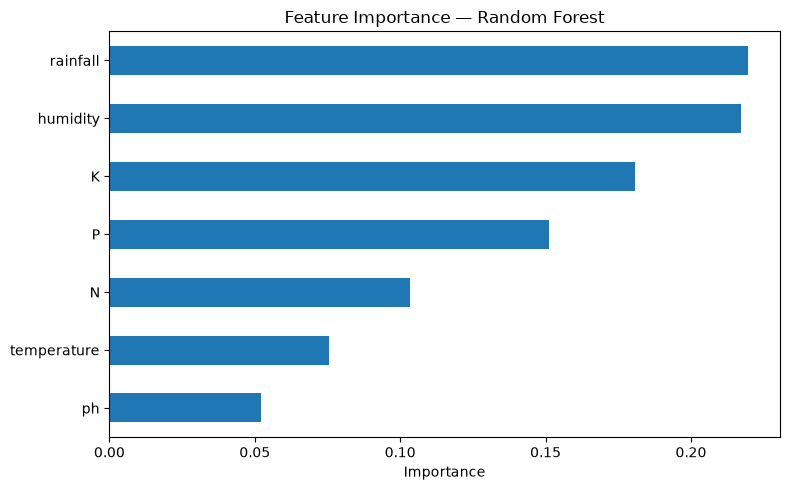

In [13]:
if best_name in ["Random Forest", "Decision Tree"]:
    fitted_tree = best_model
    importance = pd.Series(
        fitted_tree.feature_importances_, index=expected_features
    ).sort_values(ascending=False)
    display(importance.to_frame("importance"))
    importance.sort_values().plot(kind="barh", figsize=(8, 5))
    plt.title(f"Feature Importance — {best_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print("Feature importance is not directly available for this selected model.")

## 9. Predict a crop for a new example

In [14]:
# Replace these example values with measured values for the field you are evaluating.
# Values must use the same units and meaning as the dataset features.
sample = pd.DataFrame([{
    "N": 90,
    "P": 42,
    "K": 43,
    "temperature": 23.5,
    "humidity": 80.0,
    "ph": 6.5,
    "rainfall": 200.0
}])

predicted_crop = best_model.predict(sample[expected_features])[0]
print("Recommended crop for the supplied example:", predicted_crop)

Recommended crop for the supplied example: rice


## 10. Save the selected model and test a reload

In [15]:
MODEL_PATH = "crop_recommendation_model.joblib"
joblib.dump(best_model, MODEL_PATH)
print("Saved model to:", MODEL_PATH)

loaded_model = joblib.load(MODEL_PATH)
print("Reload test prediction:", loaded_model.predict(sample[expected_features])[0])

Saved model to: crop_recommendation_model.joblib
Reload test prediction: rice


## 11. Export the application and project files

Run this cell after the model training, evaluation, and model-saving cells. It creates the Streamlit frontend (`app.py`), the current-run model metrics, the cleaned dataset copy, and project documentation. It does not embed any previously displayed notebook results.

In [16]:
# Export the files required by the Streamlit frontend.
# Run this cell only after all model-training and evaluation cells have completed.

import os
import joblib
import pandas as pd

FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]

# Save the model selected by the current notebook run.
joblib.dump(best_model, "crop_recommendation_model.joblib")

# Save the cleaned dataset used in this run.
df.to_csv("Crop_recommendation.csv", index=False)

# Save freshly calculated evaluation metrics (not old notebook output).
results_df.to_csv("model_results.csv", index=False)

# Save the frontend source code.
app_source = r"""import os
import joblib
import pandas as pd
import streamlit as st
import plotly.express as px

st.set_page_config(
    page_title="Crop Recommendation System",
    page_icon="🌱",
    layout="wide",
    initial_sidebar_state="expanded"
)

MODEL_FILE = "crop_recommendation_model.joblib"
DATA_FILE = "Crop_recommendation.csv"
RESULTS_FILE = "model_results.csv"
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]

st.markdown(\"\"\"
<style>
    .stApp {background: linear-gradient(180deg, #f5fbf5 0%, #ffffff 48%);}
    [data-testid="stSidebar"] {background-color: #eaf5e9;}
    .hero {
        padding: 1.6rem 1.8rem; border-radius: 18px;
        background: linear-gradient(120deg, #14532d, #23834a);
        color: white; margin-bottom: 1.2rem;
    }
    .hero h1 {color: white; margin-bottom: .3rem;}
    .hero p {color: #e8f5e9; font-size: 1.05rem;}
    .result {
        padding: 1.4rem; border-radius: 16px; text-align: center;
        background: #e8f5e9; border: 1px solid #b7dfbd;
    }
    .result h2 {color: #14532d; font-size: 2rem;}
    div.stButton > button[kind="primary"] {
        background: #19733a; border-color: #19733a; color: white;
    }
</style>
\"\"\", unsafe_allow_html=True)

@st.cache_resource
def get_model():
    return joblib.load(MODEL_FILE)

@st.cache_data
def get_data():
    return pd.read_csv(DATA_FILE)

def show_setup_error():
    missing = [f for f in [MODEL_FILE, DATA_FILE] if not os.path.exists(f)]
    if missing:
        st.error("Required project file(s) not found: " + ", ".join(missing))
        st.info("Run the complete Google Colab notebook, including its final export cell, then launch Streamlit from the same folder.")
        st.stop()

show_setup_error()
model = get_model()
data = get_data()

if not set(FEATURES + ["label"]).issubset(data.columns):
    st.error("The dataset does not contain the expected feature columns and label.")
    st.stop()

st.sidebar.title("🌱 CropWise")
st.sidebar.caption("Machine Learning Based Crop Recommendation")
page = st.sidebar.radio(
    "Navigate",
    ["Home", "Crop Prediction", "Dataset Explorer", "Model Performance", "About"]
)
st.sidebar.divider()
st.sidebar.caption("Academic project prototype")

if page == "Home":
    st.markdown(\"\"\"
    <div class="hero">
      <h1>🌱 Crop Recommendation System</h1>
      <p>Make an informed crop choice using soil nutrients and weather conditions.</p>
    </div>
    \"\"\", unsafe_allow_html=True)
    st.write(
        "This application uses a supervised machine-learning model trained on "
        "labelled crop data. Enter soil and environmental measurements to obtain "
        "a predicted crop category."
    )
    a, b, c = st.columns(3)
    a.metric("Dataset records", f"{len(data):,}")
    b.metric("Crop categories", data["label"].nunique())
    c.metric("Model inputs", len(FEATURES))
    st.subheader("How to use the application")
    st.markdown(\"\"\"
    1. Open **Crop Prediction** from the sidebar.
    2. Enter the soil nutrient values: nitrogen, phosphorus and potassium.
    3. Enter temperature, humidity, soil pH and rainfall.
    4. Select **Recommend Crop** to view the model prediction.
    \"\"\")
    st.info("This is an educational decision-support prototype, not a substitute for local soil testing or advice from an agricultural expert.")

elif page == "Crop Prediction":
    st.markdown('<div class="hero"><h1>🌾 Crop Prediction</h1><p>Enter the measured soil and weather conditions.</p></div>', unsafe_allow_html=True)
    st.subheader("Soil nutrient values")
    col1, col2, col3 = st.columns(3)
    values = {}
    for col, feature, label in [
        (col1, "N", "Nitrogen (N)"),
        (col2, "P", "Phosphorus (P)"),
        (col3, "K", "Potassium (K)")
    ]:
        lo = float(data[feature].min())
        hi = float(data[feature].max())
        default = float(data[feature].median())
        values[feature] = col.number_input(label, min_value=lo, max_value=hi, value=default, key=feature)
    st.subheader("Weather and soil conditions")
    col4, col5 = st.columns(2)
    for col, feature, label in [
        (col4, "temperature", "Temperature (°C)"),
        (col5, "humidity", "Humidity (%)"),
        (col4, "ph", "Soil pH"),
        (col5, "rainfall", "Rainfall (mm)")
    ]:
        lo = float(data[feature].min())
        hi = float(data[feature].max())
        default = float(data[feature].median())
        values[feature] = col.number_input(label, min_value=lo, max_value=hi, value=default, key=feature)
    st.caption("Input limits are based on the minimum and maximum values in the supplied training dataset.")
    if st.button("🌱 Recommend Crop", type="primary", use_container_width=True):
        row = pd.DataFrame([[values[f] for f in FEATURES]], columns=FEATURES)
        prediction = model.predict(row)[0]
        st.markdown(
            f'<div class="result"><p>Recommended crop predicted by the model</p><h2>🌿 {str(prediction).title()}</h2></div>',
            unsafe_allow_html=True
        )
        with st.expander("View entered values"):
            st.dataframe(row, use_container_width=True)

elif page == "Dataset Explorer":
    st.markdown('<div class="hero"><h1>📊 Dataset Explorer</h1><p>Explore the dataset used to train the crop classifier.</p></div>', unsafe_allow_html=True)
    m1, m2, m3 = st.columns(3)
    m1.metric("Records", f"{len(data):,}")
    m2.metric("Features", len(FEATURES))
    m3.metric("Crop classes", data["label"].nunique())
    st.subheader("Dataset preview")
    st.dataframe(data.head(15), use_container_width=True)
    st.subheader("Crop class distribution")
    counts = data["label"].value_counts().rename_axis("Crop").reset_index(name="Records")
    fig = px.bar(counts, x="Crop", y="Records", color="Records", color_continuous_scale="Greens")
    fig.update_layout(xaxis_title="Crop", yaxis_title="Number of records")
    st.plotly_chart(fig, use_container_width=True)
    st.subheader("Numerical feature summary")
    st.dataframe(data[FEATURES].describe().T, use_container_width=True)
    st.subheader("Feature correlation")
    corr = data[FEATURES].corr(numeric_only=True)
    fig2 = px.imshow(corr, text_auto=".2f", aspect="auto", color_continuous_scale="RdYlGn", zmin=-1, zmax=1)
    st.plotly_chart(fig2, use_container_width=True)

elif page == "Model Performance":
    st.markdown('<div class="hero"><h1>📈 Model Performance</h1><p>Evaluation metrics generated when the notebook is run.</p></div>', unsafe_allow_html=True)
    if os.path.exists(RESULTS_FILE):
        results = pd.read_csv(RESULTS_FILE)
        st.dataframe(results, use_container_width=True)
        metric_options = [c for c in ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"] if c in results.columns]
        if metric_options and "Model" in results.columns:
            metric = st.selectbox("Choose evaluation metric", metric_options)
            fig = px.bar(results, x="Model", y=metric, color="Model", range_y=[0, 1], title=f"{metric} by model")
            st.plotly_chart(fig, use_container_width=True)
        best = results.sort_values("F1-score (macro)", ascending=False).iloc[0] if "F1-score (macro)" in results.columns else None
        if best is not None:
            st.success(f"Best model by macro F1-score in the latest notebook run: {best['Model']}")
    else:
        st.warning("Model metrics file is not available yet. Run the full notebook and its export cell.")
    st.subheader("Algorithms included")
    st.markdown("- Decision Tree Classifier\n- Random Forest Classifier\n- K-Nearest Neighbors (KNN)\n- Support Vector Machine classification using SVC")

elif page == "About":
    st.markdown('<div class="hero"><h1>ℹ️ About the Project</h1><p>Crop Recommendation System using supervised machine learning.</p></div>', unsafe_allow_html=True)
    st.subheader("Project objective")
    st.write("To predict a suitable crop category from seven soil and weather inputs using a model trained on labelled crop records.")
    st.subheader("Input parameters")
    st.markdown(\"\"\"
    - **N, P, K:** soil nitrogen, phosphorus and potassium values
    - **Temperature:** ambient temperature
    - **Humidity:** relative humidity
    - **pH:** soil acidity/alkalinity measure
    - **Rainfall:** rainfall measurement
    \"\"\")
    st.subheader("Technology stack")
    st.markdown("Python · Pandas · Scikit-learn · Joblib · Streamlit · Plotly")
    st.warning("A model prediction is not a guarantee of yield or profitability. Real planting decisions should consider local conditions, soil tests, water availability, season, and professional agricultural guidance.")
"""
with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_source)

# Save dependency list.
requirements = """streamlit
pandas
numpy
scikit-learn
joblib
plotly
"""
with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements)

# Save project instructions.
readme = """# Crop Recommendation System

A machine-learning crop classification project with a Streamlit user interface.

## Files
- `Crop_Recommendation_System_Milestone.ipynb`: ML workflow and model training
- `app.py`: Streamlit frontend
- `crop_recommendation_model.joblib`: model selected in the latest notebook run
- `Crop_recommendation.csv`: cleaned dataset used in the latest run
- `model_results.csv`: evaluation metrics generated in the latest run
- `requirements.txt`: Python dependencies

## Run in Google Colab
1. Open the notebook and run all cells from top to bottom.
2. Run the final export cell to create the application files.
3. Install dependencies: `!pip install -r requirements.txt`
4. Start Streamlit: `!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > streamlit.log 2>&1 &`
5. In another cell run: `!npx localtunnel --port 8501`
6. Open the public URL printed by LocalTunnel. Keep the Colab runtime running.

## Run locally
1. Download all project files into the same folder.
2. Install dependencies: `pip install -r requirements.txt`
3. Run: `streamlit run app.py`
4. Open the local URL shown in the terminal (usually http://localhost:8501).

The model metrics shown by the app come from the latest notebook run. No fixed performance values are hardcoded.
"""
with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

print("Frontend and deployment files have been created for this notebook run.")
print("Files: app.py, requirements.txt, README.md, model_results.csv, Crop_recommendation.csv, crop_recommendation_model.joblib")


Frontend and deployment files have been created for this notebook run.
Files: app.py, requirements.txt, README.md, model_results.csv, Crop_recommendation.csv, crop_recommendation_model.joblib
